## Info

* data source: HGNC & ChEMBL

## data process

In [ ]:
import pandas as pd

ref_df = pd.read_csv('../UniPert/data/processed_target_info_hgnc19321.csv').drop_duplicates()
ref_df.rename(columns={'UniProt accession': 'UniProt Accessions'}, inplace=True)
ref_df.dropna(subset=['UniProt Accessions'], inplace=True)

In [ ]:
pc_df = pd.read_csv('../UniPert/data/processed_CHEMBL_single_protein_target_annotations.csv').drop_duplicates()

In [5]:
pc_df = pc_df.merge(ref_df, on='UniProt Accessions', how='outer')

In [ ]:
import pickle

file_path = '../UniPert/current_model/unipert_reps.pkl'

with open(file_path, 'rb') as f:
    try:
        reps = pickle.load(f)
    except Exception as e:
        print(f"Error reading pickle file: {str(e)}")

In [8]:
new_acc = list(set(pc_df['UniProt Accessions'].tolist()) - set(reps.keys()))
len(new_acc)

0

In [9]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.manifold import TSNE

def add_tsne_features_to_df(pc_df, unipert_reps):
    features = []
    for uid in pc_df['UniProt Accessions']:
        features.append(unipert_reps[uid])
    features = np.array(features)
    
    tsne = TSNE(
        n_components=2, 
        perplexity=30,
        early_exaggeration=12,
        learning_rate=200,
        random_state=42
        )
    tsne_result = tsne.fit_transform(features)
    
    pc_df['t-SNE_1'] = tsne_result[:, 0]
    pc_df['t-SNE_2'] = tsne_result[:, 1]
    
    return pc_df


In [11]:
pc_df_with_tsne = add_tsne_features_to_df(pc_df, reps)

In [12]:
import matplotlib.pyplot as plt

def plot_tsne_by_category(pc_df, category_col):
    plt.figure(figsize=(6, 6))
    for category in pc_df[category_col].unique():
        subset = pc_df[pc_df[category_col] == category]
        plt.scatter(subset['t-SNE_1'], 
                    subset['t-SNE_2'], 
                    label=category, 
                    alpha=0.5,
                    s=20,
                    edgecolors='black',
                    linewidths=0.1)
    
    plt.title('TSNE Clustering of Protein Categories')
    plt.xlabel('t-SNE-1')
    plt.ylabel('t-SNE-2')
    plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
    plt.show()


## Plot

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns


import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.font_manager import FontProperties, fontManager
from matplotlib.ticker import FuncFormatter

font_path = '../Helvetica.ttf' 
fontManager.addfont(font_path)
prop = FontProperties(fname=font_path)
font_name = prop.get_name()
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = [font_name] 
print("Current font settings:", plt.rcParams['font.sans-serif'])


Current font settings: ['Helvetica']


In [19]:
def plot_tsne_by_category_overall(pc_df, category_col, topk=None, default_classes=None, save=False):
    import matplotlib.pyplot as plt
    import seaborn as sns
    
    plt.figure(figsize=(6, 6))

    pc_df = pc_df.reset_index(drop=True)
    
    categories = list(pc_df[category_col].value_counts().index)
    if default_classes is not None:
        for defalut_class in default_classes:
            if defalut_class in categories:
                categories.remove(defalut_class)

    if topk is not None:
        categories = categories[:topk]

    print(categories)
    palettes = sns.color_palette("tab20b", len(categories))
    category_to_color = {category: color for category, color in zip(categories, palettes)}
    pc_df['color'] = pc_df.apply(lambda row: category_to_color.get(row[category_col], 'lightgray'), axis=1)


    pc_df['plot rank'] = [0 if isinstance(x, str) else 1 for x in list(pc_df['color'])]
    pc_df = pc_df.sort_values(by=['plot rank'])    

    plt.scatter(pc_df['t-SNE_1'], 
                pc_df['t-SNE_2'], 
                c=pc_df['color'], 
                alpha=0.6, 
                s=8, 
                edgecolors='lightgray', 
                linewidths=0.1,
                )

    handles = []
    labels = []
    for category, color in zip(categories, palettes):
        handles.append(plt.Line2D([0], [0], color=color, marker='o', linestyle='None', markersize=6))
        labels.append(category)

    plt.legend(handles, 
               labels, 
               loc='center left', 
               bbox_to_anchor=(1, 0, 0.5, 1), 
               fontsize=9,
               )
    

    plt.title('Protein Categories')
    plt.xticks([])
    plt.yticks([])
    plt.tick_params(axis='x', which='both', pad=0)  
    plt.tick_params(axis='y', which='both', pad=0)  
    plt.xlabel('tSNE1')
    plt.ylabel('tSNE2')

    if save:
        plt.savefig(save, dpi=300, bbox_inches='tight')
    plt.show()
            

In [13]:
pc_df_with_tsne['Protein families'] = pc_df_with_tsne['Protein families'].astype(str)
pc_df_with_tsne['Protein families'] = pc_df_with_tsne['Protein families'].apply(lambda x: x.replace('"', ""))
pc_df_with_tsne['Protein families'] = pc_df_with_tsne['Protein families'].apply(lambda x: x.split(", "))
pc_df_with_tsne = pc_df_with_tsne.explode('Protein families')
pc_df_with_tsne[pc_df_with_tsne['ChEMBL ID']=='CHEMBL3430873']

,ChEMBL ID,Name,UniProt Accessions,Type,Organism,Compounds,Activities,Tax ID,Species Group Flag,protein_classification_ids,...,Approved symbol,Approved name,NCBI gene ID,Ensembl gene ID,Protein names,Gene Ontology IDs,Protein families,Reactome Pathway,t-SNE_1,t-SNE_2
9768,CHEMBL3430873,"N-alpha-acetyltransferase 16, NatA auxiliary s...",Q6N069,SINGLE PROTEIN,Homo sapiens,NaN,NaN,9606.0,False,601,...,NAA16,"N-alpha-acetyltransferase 16, NatA auxiliary s...",79612.0,ENSG00000172766,"N-alpha-acetyltransferase 16, NatA auxiliary s...",GO:0005634; GO:0005667; GO:0005737; GO:0005829...,nan,NaN,-35.111019,-48.415569


In [14]:
pc_df_with_tsne['Protein families'] = pc_df_with_tsne['Protein families'].astype(str)
pc_df_with_tsne['Protein families'] = pc_df_with_tsne['Protein families'].apply(lambda x: x.replace('"', ""))
pc_df_with_tsne['Protein families'] = pc_df_with_tsne['Protein families'].apply(lambda x: x.split(", "))
pc_df_with_tsne = pc_df_with_tsne.explode('Protein families')
pc_df_with_tsne

,ChEMBL ID,Name,UniProt Accessions,Type,Organism,Compounds,Activities,Tax ID,Species Group Flag,protein_classification_ids,...,Approved symbol,Approved name,NCBI gene ID,Ensembl gene ID,Protein names,Gene Ontology IDs,Protein families,Reactome Pathway,t-SNE_1,t-SNE_2
0,NaN,NaN,A0A024R1R8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,TMA7B,translation machinery associated 7 homolog B,112268293.0,ENSG00000225528,Translation machinery-associated protein 7B,NaN,TMA7 family,NaN,41.229507,6.709191
1,NaN,NaN,A0A024RBG1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NUDT4B,nudix hydrolase 4B,440672.0,ENSG00000177144,Diphosphoinositol polyphosphate phosphohydrola...,GO:0000298; GO:0003723; GO:0005634; GO:0005737...,Nudix hydrolase family,NaN,-8.385687,24.881136
1,NaN,NaN,A0A024RBG1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NUDT4B,nudix hydrolase 4B,440672.0,ENSG00000177144,Diphosphoinositol polyphosphate phosphohydrola...,GO:0000298; GO:0003723; GO:0005634; GO:0005737...,DIPP subfamily,NaN,-8.385687,24.881136
2,NaN,NaN,A0A075B734,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,AQP7B,aquaporin 7B,100509620.0,ENSG00000259916,Aquaporin-7B,GO:0005886; GO:0006833; GO:0015204; GO:0015250...,MIP/aquaporin (TC 1.A.8) family,NaN,76.776558,-2.805788
3,NaN,NaN,A0A075B759,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,PPIAL4E,peptidylprolyl isomerase A like 4E,730262.0,ENSG00000271567,Peptidyl-prolyl cis-trans isomerase A-like 4E ...,GO:0003755; GO:0005737; GO:0006457; GO:0016018,Cyclophilin-type PPIase family,NaN,11.978248,-73.283440
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19438,CHEMBL4105929,L-lactate dehydrogenase,V9HWB9,SINGLE PROTEIN,Homo sapiens,93.0,161.0,9606.0,False,10,...,NaN,NaN,NaN,NaN,NaN,NaN,nan,NaN,-3.396085,50.841324
19439,NaN,NaN,W5XKT8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,SPACA6,sperm acrosome associated 6,147650.0,ENSG00000182310,Sperm acrosome membrane-associated protein 6 (...,GO:0002080; GO:0007342,SPACA6 family,NaN,3.483397,-27.541344
19440,NaN,NaN,W6CW81,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,PYDC5,pyrin domain containing 5,107181291.0,ENSG00000289721,Pyrin domain-containing protein 5 (Pyrin domai...,GO:0006954; GO:0031333; GO:0035458; GO:0098586...,nan,NaN,0.983024,-5.929305
19441,NaN,NaN,X6R8D5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,CIMIP3,ciliary microtubule inner protein 3,114841037.0,ENSG00000287363,Putative uncharacterized protein CIMIP3 (Cilia...,NaN,nan,NaN,56.709164,-4.559002


In [15]:
familes = [i for i in pc_df_with_tsne['Protein families'].value_counts().index if ' family' in i]
superfamiles = [i for i in pc_df_with_tsne['Protein families'].value_counts().index if ' superfamily' in i]
subfamiles = [i for i in pc_df_with_tsne['Protein families'].value_counts().index if ' subfamily' in i]
len(familes), len(superfamiles), len(subfamiles)

(4226, 51, 842)

In [16]:
family_dict = pc_df_with_tsne['Protein families'].value_counts().to_dict()

### superfamily

Current font settings: ['Helvetica']
['Protein kinase superfamily', 'Small GTPase superfamily', 'Immunoglobulin superfamily', 'TRAFAC class myosin-kinesin ATPase superfamily', 'Major facilitator superfamily', 'Class I-like SAM-binding methyltransferase superfamily', 'Class V-like SAM-binding methyltransferase superfamily', 'AB hydrolase superfamily', 'ABC transporter superfamily', 'Methyltransferase superfamily']


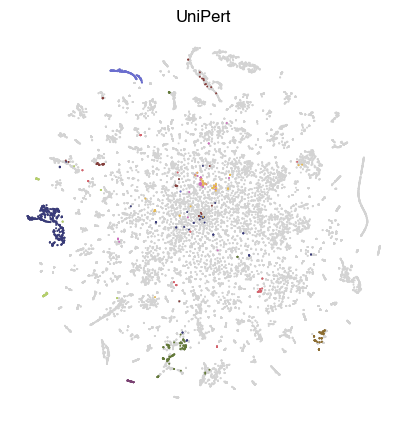

In [ ]:
pc_df = pc_df_with_tsne
category_col = 'Protein families'
topk=10
default_classes=['nan']+familes+subfamiles

plt.figure(figsize=(5, 5))

pc_df = pc_df.reset_index(drop=True)

categories = list(pc_df[category_col].value_counts().index)
if default_classes is not None:
    for defalut_class in default_classes:
        if defalut_class in categories:
            categories.remove(defalut_class)

if topk is not None:
    categories = categories[:topk]

print(categories)
palette = sns.color_palette("tab20b", 20)
palettes = [palette[i] for i in [0, 2, 4, 6, 8, 10, 12, 14, 16, 18]]
category_to_color = {category: color for category, color in zip(categories, palettes)}
pc_df['color'] = pc_df.apply(lambda row: category_to_color.get(row[category_col], 'lightgray'), axis=1)


pc_df['plot rank'] = [0 if isinstance(x, str) else 1 for x in list(pc_df['color'])]
pc_df = pc_df.sort_values(by=['plot rank'])    

# 绘制散点图
plt.scatter(pc_df['t-SNE_1'], 
            pc_df['t-SNE_2'], 
            c=pc_df['color'], 
            alpha=1, 
            s=2, 
            edgecolors='lightgray', 
            linewidths=0.0,
            )


ax = plt.gca()

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(False)

ax.set_xticks([])
ax.set_yticks([])


plt.title('UniPert', fontsize=12)
plt.xticks([])
plt.yticks([])
plt.tick_params(axis='x', which='both', pad=0)  
plt.tick_params(axis='y', which='both', pad=0)  

plt.show()

Current font settings: ['Helvetica']
['Protein kinase superfamily', 'Small GTPase superfamily', 'Immunoglobulin superfamily', 'TRAFAC class myosin-kinesin ATPase superfamily', 'Major facilitator superfamily', 'Class I-like SAM-binding methyltransferase superfamily', 'Class V-like SAM-binding methyltransferase superfamily', 'AB hydrolase superfamily', 'ABC transporter superfamily', 'Methyltransferase superfamily']


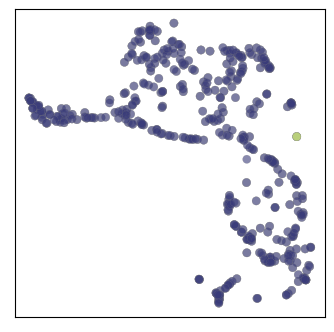

In [ ]:
pc_df = pc_df_with_tsne
category_col = 'Protein families'
topk=10
default_classes=['nan']+familes+subfamiles

plt.figure(figsize=(4, 4))

pc_df = pc_df.reset_index(drop=True)

categories = list(pc_df[category_col].value_counts().index)
if default_classes is not None:
    for defalut_class in default_classes:
        if defalut_class in categories:
            categories.remove(defalut_class)

if topk is not None:
    categories = categories[:topk]

print(categories)
palette = sns.color_palette("tab20b", 20)
palettes = [palette[i] for i in [0, 2, 4, 6, 8, 10, 12, 14, 16, 18]]
category_to_color = {category: color for category, color in zip(categories, palettes)}
pc_df['color'] = pc_df.apply(lambda row: category_to_color.get(row[category_col], 'lightgray'), axis=1)

pc_df['plot rank'] = [0 if isinstance(x, str) else 1 for x in list(pc_df['color'])]
pc_df = pc_df.sort_values(by=['plot rank'])    

pc_df = pc_df[(pc_df['t-SNE_1'] > -100) & (pc_df['t-SNE_1'] < -75)]
pc_df = pc_df[(pc_df['t-SNE_2'] > -15) & (pc_df['t-SNE_2'] < 10)]

plt.scatter(pc_df['t-SNE_1'], 
            pc_df['t-SNE_2'], 
            c=pc_df['color'], 
            alpha=0.6, 
            s=36, 
            edgecolors='gray', 
            linewidths=0.2,
            )

ax = plt.gca()

ax.set_xticks([])
ax.set_yticks([])

plt.xticks([])
plt.yticks([])
plt.tick_params(axis='x', which='both', pad=0) 
plt.tick_params(axis='y', which='both', pad=0)  


plt.show()
        

### family

20


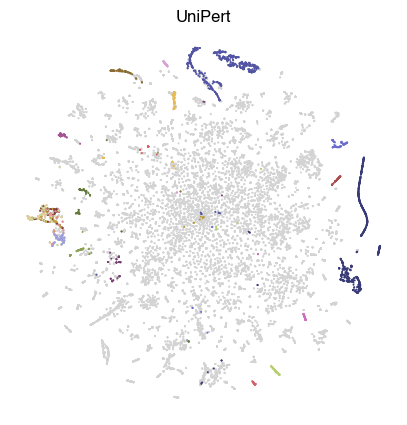

In [ ]:
pc_df = pc_df_with_tsne
category_col = 'Protein families'
topk=20
default_classes=['nan']+superfamiles+subfamiles

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(5, 5))

pc_df = pc_df.reset_index(drop=True)

categories = list(pc_df[category_col].value_counts().index)
if default_classes is not None:
    for defalut_class in default_classes:
        if defalut_class in categories:
            categories.remove(defalut_class)

if topk is not None:
    categories = categories[:topk]

print(len(categories))

palettes = sns.color_palette("tab20b", len(categories))
category_to_color = {category: color for category, color in zip(categories, palettes)}
pc_df['color'] = pc_df.apply(lambda row: category_to_color.get(row[category_col], 'lightgray'), axis=1)

pc_df['plot rank'] = [0 if isinstance(x, str) else 1 for x in list(pc_df['color'])]
pc_df = pc_df.sort_values(by=['plot rank'])    

plt.scatter(pc_df['t-SNE_1'], 
            pc_df['t-SNE_2'], 
            c=pc_df['color'], 
            alpha=1, 
            s=2, 
            edgecolors='lightgray', 
            linewidths=0.0,
            )


ax = plt.gca()

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.set_xticks([])
ax.set_yticks([])

plt.title('UniPert')
plt.xticks([])
plt.yticks([])
plt.tick_params(axis='x', which='both', pad=0) 
plt.tick_params(axis='y', which='both', pad=0)  

plt.show()
        

Current font settings: ['Helvetica']
20


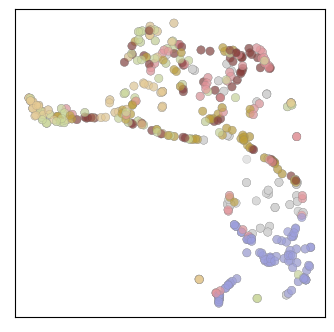

In [ ]:
pc_df = pc_df_with_tsne
category_col = 'Protein families'
topk=20
default_classes=['nan']+superfamiles+subfamiles

plt.figure(figsize=(4, 4))

pc_df = pc_df.reset_index(drop=True)

categories = list(pc_df[category_col].value_counts().index)
if default_classes is not None:
    for defalut_class in default_classes:
        if defalut_class in categories:
            categories.remove(defalut_class)

if topk is not None:
    categories = categories[:topk]

print(len(categories))
palettes = sns.color_palette("tab20b", len(categories))
category_to_color = {category: color for category, color in zip(categories, palettes)}
pc_df['color'] = pc_df.apply(lambda row: category_to_color.get(row[category_col], 'lightgray'), axis=1)


pc_df['plot rank'] = [0 if isinstance(x, str) else 1 for x in list(pc_df['color'])]
pc_df = pc_df.sort_values(by=['plot rank'])    

pc_df = pc_df[(pc_df['t-SNE_1'] > -100) & (pc_df['t-SNE_1'] < -75)]
pc_df = pc_df[(pc_df['t-SNE_2'] > -15) & (pc_df['t-SNE_2'] < 10)]

plt.scatter(pc_df['t-SNE_1'], 
            pc_df['t-SNE_2'], 
            c=pc_df['color'], 
            alpha=0.6, 
            s=36, 
            edgecolors='gray', 
            linewidths=0.2,
            )

ax.set_xticks([])
ax.set_yticks([])

plt.xticks([])
plt.yticks([])
plt.tick_params(axis='x', which='both', pad=0) 
plt.tick_params(axis='y', which='both', pad=0) 

plt.show()
        

### subfamily

['CDC2/CDKX subfamily', 'STE20 subfamily', 'Non-receptor class dual specificity subfamily', 'USP17 subfamily', 'Adhesion G-protein coupled receptor (ADGR) subfamily', 'GalNAc-T subfamily', 'DEAH subfamily', 'NR1 subfamily', 'Gamma-aminobutyric acid receptor (TC 1.A.9.5) subfamily', 'MAP kinase kinase kinase subfamily']


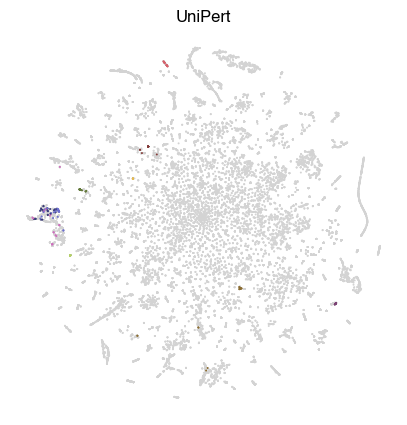

In [ ]:
pc_df = pc_df_with_tsne
category_col = 'Protein families'
topk=10
default_classes=['nan']+superfamiles+familes

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(5, 5))

pc_df = pc_df.reset_index(drop=True)

categories = list(pc_df[category_col].value_counts().index)
if default_classes is not None:
    for defalut_class in default_classes:
        if defalut_class in categories:
            categories.remove(defalut_class)

if topk is not None:
    categories = categories[:topk]

print(categories)
palette = sns.color_palette("tab20b", 20)
palettes = [palette[i] for i in [0, 2, 4, 6, 8, 10, 12, 14, 16, 18]]
category_to_color = {category: color for category, color in zip(categories, palettes)}
pc_df['color'] = pc_df.apply(lambda row: category_to_color.get(row[category_col], 'lightgray'), axis=1)


pc_df['plot rank'] = [0 if isinstance(x, str) else 1 for x in list(pc_df['color'])]
pc_df = pc_df.sort_values(by=['plot rank'])    

plt.scatter(pc_df['t-SNE_1'], 
            pc_df['t-SNE_2'], 
            c=pc_df['color'], 
            alpha=1, 
            s=2, 
            edgecolors='lightgray', 
            linewidths=0.0,
            )


ax = plt.gca()

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.set_xticks([])
ax.set_yticks([])

plt.title('UniPert')
plt.xticks([])
plt.yticks([])
plt.tick_params(axis='x', which='both', pad=0)  
plt.tick_params(axis='y', which='both', pad=0) 

plt.show()
        

Current font settings: ['Helvetica']
['CDC2/CDKX subfamily', 'STE20 subfamily', 'Non-receptor class dual specificity subfamily', 'USP17 subfamily', 'Adhesion G-protein coupled receptor (ADGR) subfamily', 'GalNAc-T subfamily', 'DEAH subfamily', 'NR1 subfamily', 'Gamma-aminobutyric acid receptor (TC 1.A.9.5) subfamily', 'MAP kinase kinase kinase subfamily']
1265


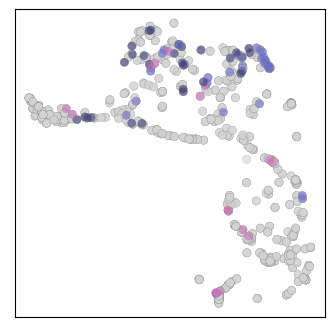

In [ ]:
pc_df = pc_df_with_tsne
category_col = 'Protein families'
topk=10
default_classes=['nan']+superfamiles+familes

plt.figure(figsize=(4, 4))

pc_df = pc_df.reset_index(drop=True)

categories = list(pc_df[category_col].value_counts().index)
if default_classes is not None:
    for defalut_class in default_classes:
        if defalut_class in categories:
            categories.remove(defalut_class)

if topk is not None:
    categories = categories[:topk]

print(categories)
palette = sns.color_palette("tab20b", 20)
palettes = [palette[i] for i in [0, 2, 4, 6, 8, 10, 12, 14, 16, 18]]

category_to_color = {category: color for category, color in zip(categories, palettes)}
pc_df['color'] = pc_df.apply(lambda row: category_to_color.get(row[category_col], 'lightgray'), axis=1)

pc_df['plot rank'] = [0 if isinstance(x, str) else 1 for x in list(pc_df['color'])]
pc_df = pc_df.sort_values(by=['plot rank'])    

pc_df = pc_df[(pc_df['t-SNE_1'] > -100) & (pc_df['t-SNE_1'] < -75)]
pc_df = pc_df[(pc_df['t-SNE_2'] > -15) & (pc_df['t-SNE_2'] < 10)]

plt.scatter(pc_df['t-SNE_1'], 
            pc_df['t-SNE_2'], 
            c=pc_df['color'], 
            alpha=0.6, 
            s=36, 
            edgecolors='gray', 
            linewidths=0.2,
            )

print(len(pc_df))

ax = plt.gca()

ax.set_xticks([])
ax.set_yticks([])

plt.xticks([])
plt.yticks([])
plt.tick_params(axis='x', which='both', pad=0)  # 调整x轴标签的间距
plt.tick_params(axis='y', which='both', pad=0)  # 调整y轴标签的间距

plt.show()
        

## Overall plot

['Protein kinase superfamily', 'Small GTPase superfamily', 'Immunoglobulin superfamily', 'TRAFAC class myosin-kinesin ATPase superfamily', 'Major facilitator superfamily', 'Class I-like SAM-binding methyltransferase superfamily', 'Class V-like SAM-binding methyltransferase superfamily', 'AB hydrolase superfamily', 'ABC transporter superfamily', 'Methyltransferase superfamily']


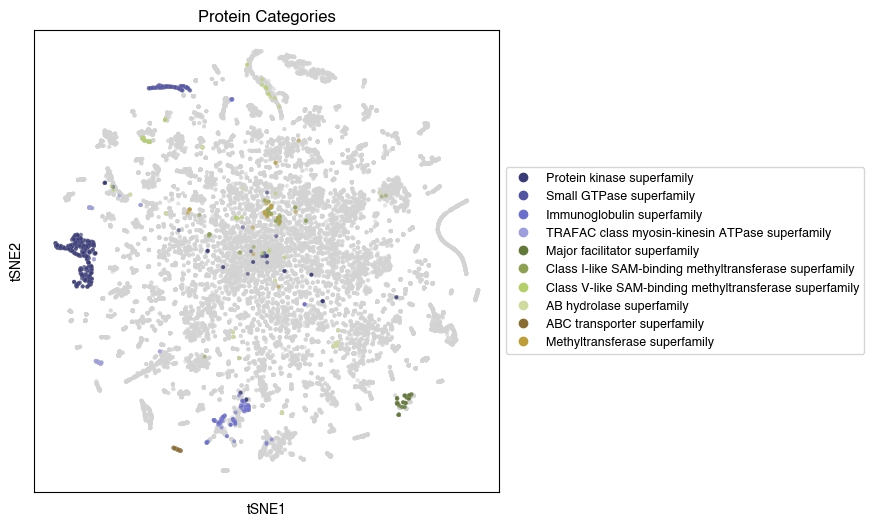

In [21]:
plot_tsne_by_category_overall(pc_df_with_tsne, 'Protein families', topk=10, default_classes=['nan']+familes+subfamiles)

['G-protein coupled receptor 1 family', 'Krueppel C2H2-type zinc-finger protein family', 'Peptidase S1 family', 'Tyr protein kinase family', 'Protein-tyrosine phosphatase family', 'Peptidase C19 family', 'Intermediate filament family', 'CAMK Ser/Thr protein kinase family', 'Rab family', 'Ser/Thr protein kinase family', 'TRIM/RBCC family', 'AGC Ser/Thr protein kinase family', 'CMGC Ser/Thr protein kinase family', 'Cytochrome P450 family', 'DEAD box helicase family', 'STE Ser/Thr protein kinase family', 'BZIP family', 'Short-chain dehydrogenases/reductases (SDR) family', 'Mitochondrial carrier (TC 2.A.29) family', 'Nuclear hormone receptor family']


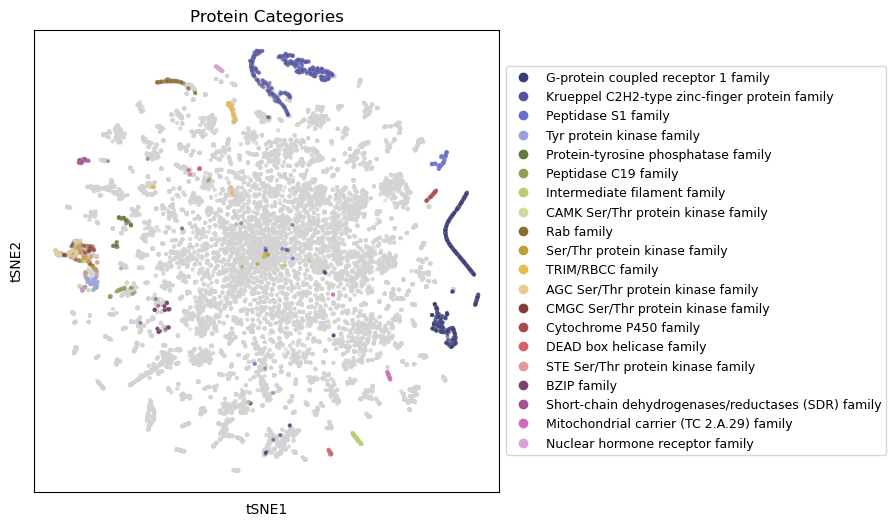

In [116]:
plot_tsne_by_category_overall(pc_df_with_tsne, 'Protein families', topk=20, default_classes=['nan']+superfamiles+subfamiles)

['STE20 subfamily', 'CDC2/CDKX subfamily', 'Non-receptor class dual specificity subfamily', 'USP17 subfamily', 'Adhesion G-protein coupled receptor (ADGR) subfamily', 'GalNAc-T subfamily', 'DEAH subfamily', 'NR1 subfamily', 'Gamma-aminobutyric acid receptor (TC 1.A.9.5) subfamily', 'MAP kinase kinase kinase subfamily']


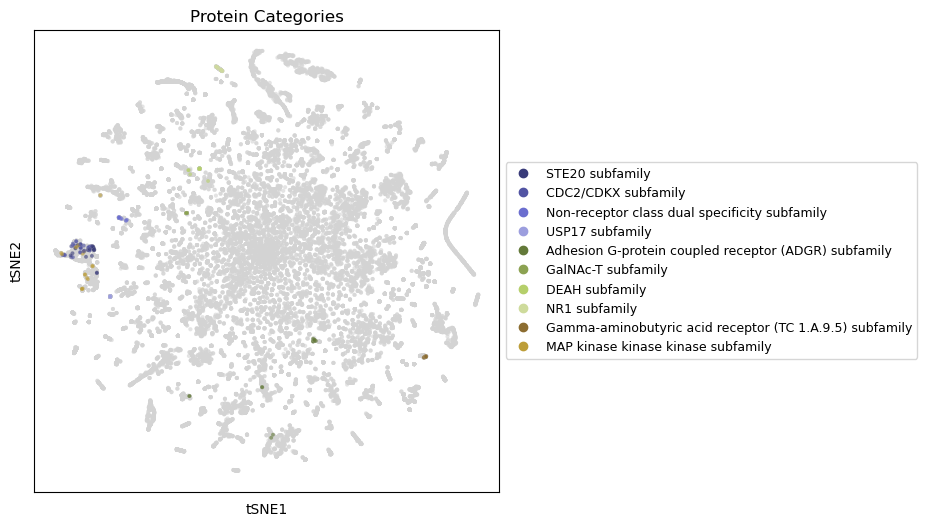

In [78]:
plot_tsne_by_category_overall(pc_df_with_tsne, 'Protein families', topk=10, default_classes=['nan']+superfamiles+familes)